# DSA4213 Assignment 1: Language Models, Embeddings and Representations

| Section | Content |
|---|---|
| 0 | Setup, data and preprocessing, sanity checks |
| 1 | **Part I**: n-gram, RNN, LSTM, Transformer language models trained on the same corpus |
| 2 | **Part II**: own Skip-gram and public GloVe input embeddings (frozen) vs random (trainable), LSTM |
| 3 | Shared evaluation (perplexity, inference cost) and generation for all models |
| 4 | Part I and II results: tables, loss curves, generated text |
| 5 | **Part III**: SST-2 sentiment from frozen LM representations |
| 6 | Cross-part comparison |

**Comparison question.** On a small single-author corpus, does model quality depend more on the architecture or on what
the input embeddings already know, and does better next-token prediction give better sentence representations?

**Attribution.** Libraries: PyTorch, gensim, scikit-learn, NLTK, HuggingFace `datasets`. Claude Code (Anthropic) was used
as a coding assistant and for debugging; see the tool-use statement in the report.

**Data (all public, downloaded automatically).** Austen novels via `nltk.download('gutenberg')`; GloVe 6B-100d via
`gensim.downloader` (`glove-wiki-gigaword-100`); SST-2 via `datasets` (`nyu-mll/glue`, `sst2`).

**Reproducibility.** Seed 42 everywhere; dependencies in `requirements.txt`
(`pip install torch==2.14.1 --index-url https://download.pytorch.org/whl/cu126` for the CUDA build). Start Jupyter from
the repository root so relative paths resolve.

In [1]:
import io, json, math, os, pickle, random, re, statistics, time
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

ROOT = Path.cwd()                       # run Jupyter from the repository root
DATA = ROOT / "data"
for d in ["data", "results", "checkpoints", "report/figures"]:
    (ROOT / d).mkdir(parents=True, exist_ok=True)

RERUN_LR_SWEEP = False   # True: re-run the 6 learning-rate sweep runs (about 12 extra minutes)
SEED = 42
print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available(),
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

torch 2.14.1+cu126 | CUDA: True NVIDIA GeForce RTX 4060 Laptop GPU


## 0. Data and preprocessing

Three Jane Austen novels (*Emma*, *Persuasion*, *Sense and Sensibility*). Each novel is split into chapters and chapters
are assigned **contiguously** 80/10/10 to train/valid/test (per novel), so no passage crosses splits. Text is lowercased,
tokenised with NLTK (punctuation kept), `<eos>` is added after each sentence, and the vocabulary is built from the
**train split only** (frequency >= 3, everything else is `<unk>`). All models share this vocabulary.

In [2]:
import pickle
import re
from collections import Counter
from pathlib import Path

import nltk
import torch
from nltk.corpus import gutenberg

BOOKS = ["austen-emma.txt", "austen-persuasion.txt", "austen-sense.txt"]
SPECIALS = ["<pad>", "<unk>", "<eos>"]
PAD, UNK, EOS = 0, 1, 2
MIN_FREQ = 3
CHAPTER_RE = re.compile(r"\n\s*(?:CHAPTER|Chapter) [IVXLC0-9]+\.?\s*\n")


def ensure_nltk():
    for pkg, path in [("gutenberg", "corpora/gutenberg"), ("punkt", "tokenizers/punkt"),
                      ("punkt_tab", "tokenizers/punkt_tab")]:
        try:
            nltk.data.find(path)
        except LookupError:
            nltk.download(pkg, quiet=True)


ABBREV = {"mr.", "mrs.", "dr.", "st.", "..."}


def split_trailing_period(words):
    """Punkt misses some sentence breaks (e.g. 'Mr. Knightley. She'), leaving 'knightley.'."""
    out = []
    for w in words:
        if len(w) > 2 and w.endswith(".") and w not in ABBREV:
            out.extend([w[:-1], "."])
        else:
            out.append(w)
    return out


def tokenize(text):
    """Lowercase, sentence-split, word-tokenize; append <eos> after each sentence.
    Underscores (Gutenberg's italics markup, e.g. _she_) are removed."""
    tokens = []
    for sent in nltk.sent_tokenize(text.replace("\n", " ").replace("_", "")):
        words = split_trailing_period(nltk.word_tokenize(sent.lower()))
        if words:
            tokens.extend(words + ["<eos>"])
    return tokens


def split_chapters(raw):
    chapters = CHAPTER_RE.split(raw)[1:]  # drop the title/volume header
    return [c for c in chapters if c.strip()]


def load_splits(ratios=(0.8, 0.1, 0.1)):
    """Return dict split -> list of tokens (concatenated across books)."""
    ensure_nltk()
    splits = {"train": [], "valid": [], "test": []}
    for book in BOOKS:
        chapters = split_chapters(gutenberg.raw(book))
        n = len(chapters)
        n_train = round(n * ratios[0])
        n_valid = round(n * ratios[1])
        parts = {"train": chapters[:n_train],
                 "valid": chapters[n_train:n_train + n_valid],
                 "test": chapters[n_train + n_valid:]}
        for name, chs in parts.items():
            for ch in chs:
                splits[name].extend(tokenize(ch))
    return splits


class Vocab:
    def __init__(self, tokens, min_freq=MIN_FREQ):
        counts = Counter(tokens)
        words = sorted((w for w, c in counts.items() if c >= min_freq and w not in SPECIALS),
                       key=lambda w: (-counts[w], w))
        self.itos = SPECIALS + words
        self.stoi = {w: i for i, w in enumerate(self.itos)}
        self.counts = counts

    def __len__(self):
        return len(self.itos)

    def encode(self, tokens):
        return [self.stoi.get(t, UNK) for t in tokens]

    def decode(self, ids):
        return [self.itos[i] for i in ids]


CACHE = ROOT / "data" / "austen_splits.pkl"


def build_corpus():
    """Tokenized splits, vocab (from train only) and id tensors."""
    if CACHE.exists():
        splits = pickle.loads(CACHE.read_bytes())
    else:
        splits = load_splits()
        CACHE.parent.mkdir(exist_ok=True)
        CACHE.write_bytes(pickle.dumps(splits))
    vocab = Vocab(splits["train"])
    ids = {k: torch.tensor(vocab.encode(v), dtype=torch.long) for k, v in splits.items()}
    return splits, vocab, ids


def batchify(data, batch_size):
    """Reshape a 1-D token stream into (batch_size, n_steps) contiguous streams."""
    n = data.size(0) // batch_size
    return data[: n * batch_size].view(batch_size, n)


def lm_chunks(stream, seq_len):
    """Yield (x, y) chunks of shape (B, <=seq_len); y is x shifted by one."""
    for i in range(0, stream.size(1) - 1, seq_len):
        L = min(seq_len, stream.size(1) - 1 - i)
        yield stream[:, i:i + L], stream[:, i + 1:i + 1 + L]

In [3]:
splits, vocab, ids = build_corpus()
print(f"vocab size (min_freq={MIN_FREQ}): {len(vocab)}")
for k, v in ids.items():
    print(f"{k:5s}: {len(v):7d} tokens, <unk> rate {(v == UNK).float().mean().item():.2%}")
print("sample:", " ".join(splits["train"][:40]))

vocab size (min_freq=3): 4667
train:  340494 tokens, <unk> rate 1.85%
valid:   56886 tokens, <unk> rate 2.66%
test :   50489 tokens, <unk> rate 2.84%
sample: emma woodhouse , handsome , clever , and rich , with a comfortable home and happy disposition , seemed to unite some of the best blessings of existence ; and had lived nearly twenty-one years in the world with very


## 1. Part I: language models on the same corpus

### 1.1 Interpolated Kneser-Ney trigram

Absolute discounting with continuation counts (Chen & Goodman, 1998); a single discount *d* is tuned on the validation set.
The text is one continuous stream (`<eos>` is an ordinary token), the same view the neural models get.

In [4]:
import json
import math
import time
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np



class KNTrigram:
    def __init__(self, ids, vocab_size, d=0.75):
        self.V = vocab_size
        self.d = d
        tri = Counter(zip(ids, ids[1:], ids[2:]))
        bi = Counter(zip(ids, ids[1:]))
        # highest order: raw counts
        self.c_uvw = tri
        self.c_uv = Counter()             # c(u v .)
        self.n_uv = Counter()             # N1+(u v .)
        self.follow_uv = defaultdict(dict)
        for (u, v, w), c in tri.items():
            self.c_uv[(u, v)] += c
            self.n_uv[(u, v)] += 1
            self.follow_uv[(u, v)][w] = c
        # middle order: continuation counts N1+(. v w)
        self.cc_vw = Counter()
        for (u, v, w) in tri:
            self.cc_vw[(v, w)] += 1
        self.cc_v = Counter()             # sum_w N1+(. v w)
        self.n_v = Counter()              # N1+(v .) over continuation types
        self.follow_v = defaultdict(dict)
        for (v, w), c in self.cc_vw.items():
            self.cc_v[v] += c
            self.n_v[v] += 1
            self.follow_v[v][w] = c
        # lowest order: N1+(. w), interpolated with uniform
        cc_w = Counter(w for (_, w) in bi)
        self.cc_w = np.zeros(vocab_size)
        for w, c in cc_w.items():
            self.cc_w[w] = c
        self.n_bigram_types = len(bi)

    # --- full distributions (used for sampling and sanity checks) ---
    def p_uni(self):
        d, N = self.d, self.n_bigram_types
        n_types = (self.cc_w > 0).sum()
        return np.maximum(self.cc_w - d, 0) / N + d * n_types / N / self.V

    def p_bi(self, v):
        p = self.p_uni()
        tot = self.cc_v.get(v, 0)
        if tot == 0:
            return p
        out = self.d * self.n_v[v] / tot * p
        for w, c in self.follow_v[v].items():
            out[w] += max(c - self.d, 0) / tot
        return out

    def p_tri(self, u, v):
        p = self.p_bi(v)
        tot = self.c_uv.get((u, v), 0)
        if tot == 0:
            return p
        out = self.d * self.n_uv[(u, v)] / tot * p
        for w, c in self.follow_uv[(u, v)].items():
            out[w] += max(c - self.d, 0) / tot
        return out

    # --- single probabilities (fast path for evaluation) ---
    def prob(self, u, v, w):
        d = self.d
        N = self.n_bigram_types
        p = max(self.cc_w[w] - d, 0) / N + d * self._n_uni_types / N / self.V
        tot = self.cc_v.get(v, 0)
        if tot:
            p = max(self.follow_v[v].get(w, 0) - d, 0) / tot + d * self.n_v[v] / tot * p
        if u is not None:
            tot = self.c_uv.get((u, v), 0)
            if tot:
                p = max(self.follow_uv[(u, v)].get(w, 0) - d, 0) / tot + d * self.n_uv[(u, v)] / tot * p
        return p

    @property
    def _n_uni_types(self):
        if not hasattr(self, "_nut"):
            self._nut = int((self.cc_w > 0).sum())
        return self._nut

    def cross_entropy(self, ids):
        """Average NLL (nats) over targets ids[1:], i.e. every token after the first."""
        nll = -math.log(self.prob(None, ids[0], ids[1]))
        for i in range(2, len(ids)):
            nll -= math.log(self.prob(ids[i - 2], ids[i - 1], ids[i]))
        return nll / (len(ids) - 1)

    def generate(self, prompt_ids, n_tokens, rng, temperature=0.8, top_k=40, greedy=False,
                 banned=(0,)):
        out = list(prompt_ids)
        for _ in range(n_tokens):
            u = out[-2] if len(out) >= 2 else None
            p = self.p_tri(u, out[-1]) if u is not None else self.p_bi(out[-1])
            out.append(sample_from_probs(p, rng, temperature, top_k, greedy, banned))
        return out[len(prompt_ids):]


def sample_from_probs(p, rng, temperature, top_k, greedy, banned=(0,)):
    """Temperature + top-k sampling from a probability vector (shared with neural decoding)."""
    logits = np.log(np.asarray(p, dtype=np.float64) + 1e-12)
    logits[list(banned)] = -np.inf
    if greedy:
        return int(np.argmax(logits))
    logits = logits / temperature
    if top_k:
        kth = np.sort(logits)[-top_k]
        logits[logits < kth] = -np.inf
    q = np.exp(logits - logits.max())
    q /= q.sum()
    return int(rng.choice(len(q), p=q))


def run_ngram(out=ROOT / "results" / "ngram.json"):

    _, vocab, ids = build_corpus()
    train, valid, test = (ids[k].tolist() for k in ("train", "valid", "test"))

    t0 = time.perf_counter()
    model = KNTrigram(train, len(vocab))
    count_time = time.perf_counter() - t0

    # tune the discount on validation
    grid = {}
    for d in [0.5, 0.6, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95]:
        model.d = d
        grid[d] = model.cross_entropy(valid)
        print(f"d={d:.2f}  valid ppl={math.exp(grid[d]):.2f}")
    best_d = min(grid, key=grid.get)
    model.d = best_d

    # sanity: distribution sums to one
    s = model.p_tri(train[0], train[1]).sum()
    assert abs(s - 1) < 1e-6, s

    t0 = time.perf_counter()
    test_ce = model.cross_entropy(test)
    infer_time = time.perf_counter() - t0
    n_params = len(model.c_uvw) + len(model.cc_vw) + int((model.cc_w > 0).sum())
    res = {
        "model": "ngram", "d": best_d, "valid_grid": {str(k): v for k, v in grid.items()},
        "valid_ce": grid[best_d], "test_ce": test_ce, "test_ppl": math.exp(test_ce),
        "train_time_s": count_time, "n_params": n_params,
        "infer_time_s": infer_time, "infer_tokens_per_s": (len(test) - 1) / infer_time,
    }
    print(json.dumps(res, indent=2))
    import os
    os.makedirs(os.path.dirname(out), exist_ok=True)
    with open(out, "w") as f:
        json.dump(res, f, indent=2)

In [5]:
run_ngram()

d=0.50  valid ppl=99.38


d=0.60  valid ppl=92.76


d=0.70  valid ppl=88.32


d=0.75  valid ppl=86.79


d=0.80  valid ppl=85.70


d=0.85  valid ppl=85.12


d=0.90  valid ppl=85.17


d=0.95  valid ppl=86.27


{
  "model": "ngram",
  "d": 0.85,
  "valid_grid": {
    "0.5": 4.598955226275116,
    "0.6": 4.53003254555641,
    "0.7": 4.481012706545189,
    "0.75": 4.463490276453994,
    "0.8": 4.450909867038003,
    "0.85": 4.444040833116833,
    "0.9": 4.444649216861583,
    "0.95": 4.457439842656402
  },
  "valid_ce": 4.444040833116833,
  "test_ce": 4.473259371172795,
  "test_ppl": 87.64191551981935,
  "train_time_s": 1.3976228999672458,
  "n_params": 299760,
  "infer_time_s": 0.8186830000486225,
  "infer_tokens_per_s": 61669.779385917944
}


### 1.2 Neural models: RNN, LSTM, Transformer

All three use **100-d randomly initialised, trainable** input embeddings (an optional `emb_weights` + `freeze_emb` is used
in Part II). The LSTM is two stacked single-layer `nn.LSTM`s with explicit dropout between layers, which is equivalent to
`nn.LSTM(num_layers=2, dropout=p)`; cuDNN's fused inter-layer dropout crashed at process exit with torch 2.14.1 on Windows.
Every model exposes `encode(x)` (per-token hidden states) for Part III.

In [6]:
import torch
import torch.nn as nn



def make_embedding(vocab_size, emb_dim, weights=None, freeze=False):
    emb = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
    if weights is not None:
        emb.weight.data.copy_(torch.as_tensor(weights, dtype=torch.float))
    emb.weight.requires_grad = not freeze
    return emb


class RecurrentLM(nn.Module):
    """Stacked single-layer cells with explicit dropout between layers. This equals
    nn.LSTM(num_layers=L, dropout=p) but avoids cuDNN's fused inter-layer dropout, which
    crashed the process at exit with torch 2.14.1+cu126 on Windows."""

    def __init__(self, cell, vocab_size, emb_dim=100, hidden=256, layers=1, dropout=0.3,
                 emb_weights=None, freeze_emb=False):
        super().__init__()
        self.embed = make_embedding(vocab_size, emb_dim, emb_weights, freeze_emb)
        rnn_cls = {"rnn": nn.RNN, "lstm": nn.LSTM}[cell]
        self.layers = nn.ModuleList(
            [rnn_cls(emb_dim if i == 0 else hidden, hidden, batch_first=True) for i in range(layers)])
        self.drop = nn.Dropout(dropout)
        self.out = nn.Linear(hidden, vocab_size)
        self.hidden_dim = hidden

    def encode(self, x, hidden=None):
        """Returns top-layer states (B, T, H) and a list with one recurrent state per layer."""
        h = self.drop(self.embed(x))
        hidden = hidden or [None] * len(self.layers)
        new_hidden = []
        for i, (layer, h0) in enumerate(zip(self.layers, hidden)):
            if i > 0:
                h = self.drop(h)
            h, hn = layer(h, h0)
            new_hidden.append(hn)
        return h, new_hidden

    def forward(self, x, hidden=None):
        h, hidden = self.encode(x, hidden)
        return self.out(self.drop(h)), hidden

    @staticmethod
    def detach(hidden):
        if hidden is None:
            return None
        return [tuple(t.detach() for t in h) if isinstance(h, tuple) else h.detach() for h in hidden]


class TransformerLM(nn.Module):
    """Pre-LN decoder-only Transformer with learned positions and a causal mask."""

    def __init__(self, vocab_size, emb_dim=100, d_model=128, heads=4, layers=4, ff=512,
                 context=64, dropout=0.2, emb_weights=None, freeze_emb=False):
        super().__init__()
        self.embed = make_embedding(vocab_size, emb_dim, emb_weights, freeze_emb)
        self.proj = nn.Linear(emb_dim, d_model)
        self.pos = nn.Embedding(context, d_model)
        block = nn.TransformerEncoderLayer(d_model, heads, ff, dropout, batch_first=True,
                                           norm_first=True, activation="gelu")
        self.blocks = nn.TransformerEncoder(block, layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)
        self.out = nn.Linear(d_model, vocab_size)
        self.context = context
        self.hidden_dim = d_model

    def encode(self, x, hidden=None):
        T = x.size(1)
        assert T <= self.context, f"sequence length {T} exceeds context {self.context}"
        pos = torch.arange(T, device=x.device)
        h = self.drop(self.proj(self.embed(x)) + self.pos(pos))
        mask = nn.Transformer.generate_square_subsequent_mask(T, device=x.device)
        h = self.blocks(h, mask=mask, is_causal=True)
        return self.norm(h), None

    def forward(self, x, hidden=None):
        h, _ = self.encode(x)
        return self.out(h), None

    @staticmethod
    def detach(hidden):
        return None


CONFIGS = {
    "rnn": dict(cell="rnn", hidden=256, layers=1, dropout=0.3),
    "lstm": dict(cell="lstm", hidden=256, layers=2, dropout=0.3),
    "transformer": dict(d_model=128, heads=4, layers=4, ff=512, context=64, dropout=0.2),
}


def build_model(name, vocab_size, emb_dim=100, emb_weights=None, freeze_emb=False):
    cfg = CONFIGS[name]
    if name == "transformer":
        return TransformerLM(vocab_size, emb_dim, emb_weights=emb_weights, freeze_emb=freeze_emb, **cfg)
    return RecurrentLM(vocab_size=vocab_size, emb_dim=emb_dim, emb_weights=emb_weights,
                       freeze_emb=freeze_emb, **cfg)


def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

### 1.3 Sanity checks

Causality (changing future tokens must not change earlier logits), padding excluded from the loss, n-gram distributions sum
to one, frozen embeddings really stay frozen.

In [7]:
import sys
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn

V = 50


def _rand_ids(T, seed=0):
    g = torch.Generator().manual_seed(seed)
    return torch.randint(3, V, (2, T), generator=g)


def test_models_are_causal():
    """Changing tokens after position t must not change the logits at positions <= t."""
    for name in ["rnn", "lstm", "transformer"]:
        torch.manual_seed(0)
        m = build_model(name, V).eval()
        x = _rand_ids(20)
        x2 = x.clone()
        x2[:, 12:] = _rand_ids(8, seed=1)
        with torch.no_grad():
            a, _ = m(x)
            b, _ = m(x2)
        assert torch.allclose(a[:, :12], b[:, :12], atol=1e-5), name
        assert not torch.allclose(a[:, 12:], b[:, 12:]), name


def test_padding_excluded_from_loss():
    torch.manual_seed(0)
    logits = torch.randn(1, 6, V)
    y = torch.tensor([[5, 7, 9, PAD, PAD, PAD]])
    loss_fn = nn.CrossEntropyLoss(ignore_index=PAD)
    full = loss_fn(logits.reshape(-1, V), y.reshape(-1))
    unpadded = loss_fn(logits[:, :3].reshape(-1, V), y[:, :3].reshape(-1))
    assert torch.allclose(full, unpadded)


def test_ngram_distribution_sums_to_one():
    rng = np.random.default_rng(0)
    ids = rng.integers(1, V, 5000).tolist()
    lm = KNTrigram(ids, V, d=0.8)
    for u, v in [(ids[0], ids[1]), (3, 4), (V - 1, V - 2)]:
        p = lm.p_tri(u, v)
        assert abs(p.sum() - 1) < 1e-9
        # fast single-prob path agrees with the full distribution
        assert abs(lm.prob(u, v, 7) - p[7]) < 1e-12


def test_frozen_embedding_not_updated():
    W = np.random.default_rng(0).normal(size=(V, 100)).astype(np.float32)
    m = build_model("lstm", V, emb_weights=W, freeze_emb=True)
    opt = torch.optim.AdamW([p for p in m.parameters() if p.requires_grad], lr=1e-2)
    x = _rand_ids(10)
    logits, _ = m(x)
    logits.sum().backward()
    opt.step()
    assert np.allclose(m.embed.weight.detach().numpy(), W)

for _t in [test_models_are_causal, test_padding_excluded_from_loss, test_ngram_distribution_sums_to_one,
           test_frozen_embedding_not_updated]:
    _t()
    print("passed:", _t.__name__)

passed: test_models_are_causal
passed: test_padding_excluded_from_loss
passed: test_ngram_distribution_sums_to_one


passed: test_frozen_embedding_not_updated


### 1.4 Training procedure (shared by every neural run)

Batch of 32 parallel streams x 64-token BPTT chunks (hidden state carried across chunks for RNN/LSTM), AdamW (weight decay
0.01), 200-step warm-up then cosine decay, gradient clipping 1.0, 20 epochs, keep the checkpoint with the best validation
loss, loss excludes `<pad>`. The only per-architecture choice is the peak learning rate, picked from {1e-3, 3e-3} on
validation perplexity (sweep results in `results/lr_sweep.json`). Training time is recorded per epoch (with CUDA
synchronisation).

In [8]:
import io
import json
import math
import random
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn


HP = dict(batch_size=32, seq_len=64, epochs=20, weight_decay=0.01, warmup=200,
          clip=1.0, emb_dim=100)
LR = {"rnn": 3e-3, "lstm": 3e-3, "transformer": 1e-3}  # chosen on validation, see lr_sweep.json


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def run_name(model, emb, seed):
    name = model if emb == "random" else f"{model}_{emb}"
    return name if seed == 42 else f"{name}_s{seed}"


def load_embedding_table(emb):
    if emb == "random":
        return None, False
    return np.load(ROOT / "data" / f"{emb}_100.npy"), True


def save_checkpoint(obj, path, retries=20):
    """Serialise in memory, then write with retries: on Windows an antivirus scan of the
    previous checkpoint can briefly lock the file (error 1224)."""
    buf = io.BytesIO()
    torch.save(obj, buf)
    for attempt in range(retries):
        try:
            path.write_bytes(buf.getvalue())
            return
        except OSError:
            time.sleep(0.5)
    raise OSError(f"could not write checkpoint {path}")


@torch.no_grad()
def evaluate_chunks(model, stream, seq_len, device):
    """Mean token NLL over a batchified stream (hidden state carried for RNN/LSTM)."""
    model.eval()
    loss_fn = nn.CrossEntropyLoss(ignore_index=PAD, reduction="sum")
    total, count, hidden = 0.0, 0, None
    for x, y in lm_chunks(stream, seq_len):
        x, y = x.to(device), y.to(device)
        logits, hidden = model(x, hidden)
        total += loss_fn(logits.reshape(-1, logits.size(-1)), y.reshape(-1)).item()
        count += (y != PAD).sum().item()
    return total / count


def train_lm(model_name, emb="random", seed=42, epochs=HP["epochs"], lr=None, tag=""):
    hp = dict(HP, epochs=epochs, lr=lr or LR[model_name])

    set_seed(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    _, vocab, ids = build_corpus()
    train = batchify(ids["train"], hp["batch_size"])
    valid = batchify(ids["valid"], hp["batch_size"])

    weights, freeze = load_embedding_table(emb)
    model = build_model(model_name, len(vocab), hp["emb_dim"], weights, freeze).to(device)
    total_params, trainable = count_params(model)
    name = run_name(model_name, emb, seed) + tag
    print(f"{name}: {total_params:,} params ({trainable:,} trainable) on {device}")

    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=hp["lr"], weight_decay=hp["weight_decay"])
    steps_per_epoch = math.ceil((train.size(1) - 1) / hp["seq_len"])
    total_steps = steps_per_epoch * hp["epochs"]
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: min(1.0, (s + 1) / hp["warmup"]) *
        0.5 * (1 + math.cos(math.pi * min(s, total_steps) / total_steps)))
    loss_fn = nn.CrossEntropyLoss(ignore_index=PAD)

    log = {"name": name, "model": model_name, "emb": emb, "seed": seed, "hp": hp,
           "params_total": total_params, "params_trainable": trainable,
           "device": torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu",
           "epochs": [], "step_loss": []}
    ckpt_dir = ROOT / "checkpoints"
    ckpt_dir.mkdir(exist_ok=True)
    best = float("inf")
    train_start = time.perf_counter()
    for epoch in range(1, hp["epochs"] + 1):
        model.train()
        if device.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        hidden, ep_loss, ep_tokens, gnorms = None, 0.0, 0, []
        for x, y in lm_chunks(train, hp["seq_len"]):
            x, y = x.to(device), y.to(device)
            hidden = model.detach(hidden)
            logits, hidden = model(x, hidden)
            loss = loss_fn(logits.reshape(-1, logits.size(-1)), y.reshape(-1))
            opt.zero_grad(set_to_none=True)
            loss.backward()
            gnorms.append(nn.utils.clip_grad_norm_(params, hp["clip"]).item())
            opt.step()
            sched.step()
            n = (y != PAD).sum().item()
            ep_loss += loss.item() * n
            ep_tokens += n
            log["step_loss"].append(loss.item())
        if device.type == "cuda":
            torch.cuda.synchronize()
        ep_time = time.perf_counter() - t0
        val = evaluate_chunks(model, valid, hp["seq_len"], device)
        rec = {"epoch": epoch, "train_loss": ep_loss / ep_tokens, "valid_loss": val,
               "epoch_time_s": ep_time, "grad_norm_mean": float(np.mean(gnorms)),
               "grad_norm_max": float(np.max(gnorms))}
        log["epochs"].append(rec)
        if val < best:
            best = val
            save_checkpoint({"state_dict": model.state_dict(), "model": model_name, "emb": emb,
                             "vocab_size": len(vocab), "epoch": epoch}, ckpt_dir / f"{name}.pt")
        print(f"epoch {epoch:2d} | train {rec['train_loss']:.3f} | valid {val:.3f} "
              f"(ppl {math.exp(val):.1f}) | {ep_time:.1f}s | gnorm {rec['grad_norm_mean']:.2f}")

    log["train_time_s"] = time.perf_counter() - train_start  # includes per-epoch validation
    log["train_time_excl_valid_s"] = sum(e["epoch_time_s"] for e in log["epochs"])
    # robust cost estimate: a laptop stall can inflate single epochs (seen once: 520 s vs ~8 s)
    log["median_epoch_time_s"] = float(np.median([e["epoch_time_s"] for e in log["epochs"]]))
    log["best_valid_loss"] = best
    log["best_epoch"] = min(log["epochs"], key=lambda e: e["valid_loss"])["epoch"]
    (ROOT / "results").mkdir(exist_ok=True)
    with open(ROOT / "results" / f"train_{name}.json", "w") as f:
        json.dump(log, f, indent=1)
    print(f"best valid ppl {math.exp(best):.2f} at epoch {log['best_epoch']}")

In [9]:
for m in ["rnn", "lstm", "transformer"]:
    train_lm(m)
    print()

rnn: 1,757,767 params (1,757,767 trainable) on cuda


epoch  1 | train 6.162 | valid 4.960 (ppl 142.6) | 4.8s | gnorm 0.54


epoch  2 | train 4.836 | valid 4.575 (ppl 97.0) | 3.2s | gnorm 0.46


epoch  3 | train 4.582 | valid 4.490 (ppl 89.1) | 2.6s | gnorm 0.53


epoch  4 | train 4.460 | valid 4.439 (ppl 84.7) | 3.0s | gnorm 0.51


...

epoch 16 | train 3.972 | valid 4.303 (ppl 73.9) | 12.4s | gnorm 0.49


epoch 17 | train 3.959 | valid 4.303 (ppl 73.9) | 8.0s | gnorm 0.49


epoch 18 | train 3.952 | valid 4.303 (ppl 73.9) | 7.6s | gnorm 0.49


epoch 19 | train 3.944 | valid 4.302 (ppl 73.9) | 10.4s | gnorm 0.49


epoch 20 | train 3.942 | valid 4.302 (ppl 73.9) | 7.0s | gnorm 0.49
best valid ppl 73.85 at epoch 20



In [10]:
# Learning-rate sweep over {1e-3, 3e-3} (best validation PPL). Recorded outcome from my original sweep below;
# set RERUN_LR_SWEEP = True in the first code cell to repeat it (6 extra training runs).
LR_SWEEP = {
 "lstm": {
  "model": "lstm",
  "lr": 0.001,
  "best_valid_ppl": 79.05750024847208,
  "best_epoch": 20
 },
 "lstm_lr3e-3": {
  "model": "lstm",
  "lr": 0.003,
  "best_valid_ppl": 66.50558429533646,
  "best_epoch": 17
 },
 "rnn": {
  "model": "rnn",
  "lr": 0.001,
  "best_valid_ppl": 75.82182940257327,
  "best_epoch": 14
 },
 "rnn_lr3e-3": {
  "model": "rnn",
  "lr": 0.003,
  "best_valid_ppl": 73.9926539773845,
  "best_epoch": 20
 },
 "transformer": {
  "model": "transformer",
  "lr": 0.001,
  "best_valid_ppl": 73.85136301599276,
  "best_epoch": 20
 },
 "transformer_lr3e-3": {
  "model": "transformer",
  "lr": 0.003,
  "best_valid_ppl": 74.69155325952299,
  "best_epoch": 9
 }
}
if RERUN_LR_SWEEP:
    LR_SWEEP = {}
    for m in ["rnn", "lstm", "transformer"]:
        for lr in [1e-3, 3e-3]:
            tag = f"_lr{lr:g}"
            train_lm(m, lr=lr, tag=tag)
            log = json.load(open(ROOT / "results" / f"train_{m}{tag}.json"))
            LR_SWEEP[f"{m}{tag}"] = {"model": m, "lr": lr, "best_valid_ppl": math.exp(log["best_valid_loss"]),
                                     "best_epoch": log["best_epoch"]}
print(json.dumps(LR_SWEEP, indent=1))

{
 "lstm": {
  "model": "lstm",
  "lr": 0.001,
  "best_valid_ppl": 79.05750024847208,
  "best_epoch": 20
 },
 "lstm_lr3e-3": {
  "model": "lstm",
  "lr": 0.003,
  "best_valid_ppl": 66.50558429533646,
  "best_epoch": 17
 },
 "rnn": {
  "model": "rnn",
  "lr": 0.001,
  "best_valid_ppl": 75.82182940257327,
  "best_epoch": 14
 },
 "rnn_lr3e-3": {
  "model": "rnn",
  "lr": 0.003,
  "best_valid_ppl": 73.9926539773845,
  "best_epoch": 20
 },
 "transformer": {
  "model": "transformer",
  "lr": 0.001,
  "best_valid_ppl": 73.85136301599276,
  "best_epoch": 20
 },
 "transformer_lr3e-3": {
  "model": "transformer",
  "lr": 0.003,
  "best_valid_ppl": 74.69155325952299,
  "best_epoch": 9
 }
}


## 2. Part II: embedding variants (LSTM)

The LSTM is the Part I architecture used for the ablation. Setting 1 (random, trainable) **reuses the Part I LSTM run**
(same embedding dimension, architecture, data and training procedure). Settings 2 and 3 train two new LSTMs whose entire
input-embedding table is frozen:

* **Own Skip-gram (SGNS):** gensim Word2Vec trained on the *train split only*; its cost is reported separately.
* **Public GloVe 6B-100d:** missing words get N(0, sigma^2) rows (sigma = std of the GloVe matrix, seed 42), `<pad>` is zero.
  Vocabulary coverage is recorded.

In [11]:
import json
import time
from pathlib import Path

import numpy as np


DIM = 100
SEED = 42


def train_sentences(tokens, vocab):
    """Split the train stream at <eos>, mapping rare words to <unk> (same view the LM sees)."""
    sents, cur = [], []
    for t in tokens:
        cur.append(t if t in vocab.stoi else "<unk>")
        if t == "<eos>":
            sents.append(cur)
            cur = []
    if cur:
        sents.append(cur)
    return sents


def build_sgns(splits, vocab):
    from gensim.models import Word2Vec
    sents = train_sentences(splits["train"], vocab)
    t0 = time.perf_counter()
    w2v = Word2Vec(sents, vector_size=DIM, window=5, sg=1, negative=10, min_count=1,
                   epochs=10, workers=1, seed=SEED)
    train_time = time.perf_counter() - t0
    E = np.zeros((len(vocab), DIM), dtype=np.float32)
    missing = []
    for i, w in enumerate(vocab.itos):
        if i == PAD:
            continue
        if w in w2v.wv:
            E[i] = w2v.wv[w]
        else:
            missing.append(w)
    info = {"method": "skip-gram negative sampling (gensim)", "dim": DIM, "window": 5,
            "negative": 10, "epochs": 10, "seed": SEED, "workers": 1,
            "train_sentences": len(sents), "train_time_s": train_time,
            "missing": missing, "neighbours": neighbours(w2v.wv)}
    return E, info


def neighbours(kv, words=("elizabeth", "happy", "letter", "money", "walk", "she")):
    return {w: [n for n, _ in kv.most_similar(w, topn=5)] for w in words if w in kv}


def build_glove(vocab):
    import gensim.downloader as api
    t0 = time.perf_counter()
    kv = api.load("glove-wiki-gigaword-100")
    load_time = time.perf_counter() - t0
    sigma = float(kv.vectors.std())
    rng = np.random.default_rng(SEED)
    E = np.zeros((len(vocab), DIM), dtype=np.float32)
    missing = []
    for i, w in enumerate(vocab.itos):
        if i == PAD:
            continue
        if w in kv:
            E[i] = kv[w]
        else:
            E[i] = rng.normal(0, sigma, DIM)
            missing.append(w)
    # token-level coverage on the training stream
    train_counts = vocab.counts
    in_vocab_tokens = sum(c for w, c in train_counts.items() if w in vocab.stoi)
    unk_tokens = sum(c for w, c in train_counts.items() if w not in vocab.stoi)
    covered_tokens = sum(c for w, c in train_counts.items() if w in vocab.stoi and w in kv)
    total = in_vocab_tokens + unk_tokens
    n_types = len(vocab) - 1  # exclude <pad>
    info = {"source": "GloVe 6B 100d (glove-wiki-gigaword-100)", "load_time_s": load_time,
            "sigma": sigma, "type_coverage": 1 - len(missing) / n_types,
            "token_coverage": covered_tokens / total, "n_missing": len(missing),
            "missing": missing, "neighbours": neighbours(kv)}
    return E, info


def build_embeddings():
    splits, vocab, _ = build_corpus()
    DATA.mkdir(exist_ok=True)
    (ROOT / "results").mkdir(exist_ok=True)

    E, info = build_sgns(splits, vocab)
    np.save(DATA / "sgns_100.npy", E)
    print(f"SGNS: trained in {info['train_time_s']:.1f}s, missing {len(info['missing'])}")
    print("SGNS neighbours:", json.dumps(info["neighbours"]))
    json.dump(info, open(ROOT / "results" / "emb_sgns.json", "w"), indent=2)

    E, info = build_glove(vocab)
    np.save(DATA / "glove_100.npy", E)
    print(f"GloVe: type coverage {info['type_coverage']:.2%}, token coverage "
          f"{info['token_coverage']:.2%}, missing {info['n_missing']}: {info['missing'][:40]}")
    print("GloVe neighbours:", json.dumps(info["neighbours"]))
    json.dump(info, open(ROOT / "results" / "emb_glove.json", "w"), indent=2)

In [12]:
build_embeddings()

SGNS: trained in 29.4s, missing 0
SGNS neighbours: {"elizabeth": ["anger", "henrietta", "voluntarily", "blushed", "hayter"], "happy": ["respectably", "uncomfortable", "merry", "prudent", "unfit"], "letter": ["written", "pianoforte", "note", "sentence", "post"], "money": ["thankful", "convenience", "plenty", "quarrelled", "matches"], "walk": ["whitwell", "afternoon", "orders", "break", "chaise"], "she": ["he", "frightened", "clearly", "blushed", "utter"]}


GloVe: type coverage 97.75%, token coverage 94.23%, missing 105: ['<unk>', '<eos>', 'uppercross', 'kellynch', 'musgroves', 'donwell', 'enscombe', 'dashwoods', 'surprized', 'chuse', 'shewed', 'eltons', 'shewn', 'allenham', 'harvilles', 'shewing', 'self-command', 'stopt', 'twelvemonth', 'delaford', 'unreserve', 'court-plaister', 'dropt', 'complaisance', 'curricle', 'oftener', 'abbey-mill', 'barouche-landau', 'gentlemanlike', 'good-nature', 'monkford', "'ye", 'bragge', 'common-place', 'four-and-twenty', 'good-breeding', 'ill-disposed', 'ill-humour', 'ill-judged', 'ill-used']
GloVe neighbours: {"elizabeth": ["margaret", "mary", "catherine", "anne", "jane"], "happy": ["'m", "feel", "'re", "i", "'ll"], "letter": ["letters", "statement", "message", "issued", "memo"], "money": ["funds", "cash", "fund", "paying", "pay"], "walk": ["walking", "walks", "walked", "go", "sit"], "she": ["he", "her", "never", "mother", "then"]}


In [13]:
for emb in ["sgns", "glove"]:
    train_lm("lstm", emb=emb)
    print()

lstm_sgns: 2,559,047 params (2,092,347 trainable) on cuda


epoch  1 | train 6.404 | valid 5.854 (ppl 348.6) | 13.8s | gnorm 0.49


epoch  2 | train 5.697 | valid 5.206 (ppl 182.4) | 10.7s | gnorm 0.28


epoch  3 | train 5.090 | valid 4.791 (ppl 120.5) | 11.0s | gnorm 0.22


epoch  4 | train 4.821 | valid 4.628 (ppl 102.3) | 11.4s | gnorm 0.21


...

epoch 16 | train 4.237 | valid 4.294 (ppl 73.3) | 8.8s | gnorm 0.20


epoch 17 | train 4.227 | valid 4.293 (ppl 73.2) | 10.7s | gnorm 0.20


epoch 18 | train 4.219 | valid 4.292 (ppl 73.1) | 12.0s | gnorm 0.20


epoch 19 | train 4.216 | valid 4.292 (ppl 73.1) | 9.3s | gnorm 0.20


epoch 20 | train 4.212 | valid 4.292 (ppl 73.1) | 12.0s | gnorm 0.20
best valid ppl 73.08 at epoch 20



## 3. Shared evaluation and generation (all models)

**Prediction quality:** mean negative log-likelihood of every test token after the first, predicted from preceding tokens
only; RNN/LSTM read the stream with state carried across 64-token chunks, the Transformer uses a sliding 64-token window
with stride 32 (each scored token has >= 32 tokens of context). **Cost:** one pass over the test set as 32 streams x
64-token chunks; GPU = median of 10 passes after 3 warm-ups, CPU = median of 5 passes (4 threads).

In [14]:
import json
import math
import statistics
import time
from pathlib import Path

import torch
import torch.nn.functional as F


RUNS = ["rnn", "lstm", "transformer", "lstm_sgns", "lstm_glove"]


def load_model(name, vocab_size, device):
    ck = torch.load(ROOT / "checkpoints" / f"{name}.pt", map_location=device)
    model = build_model(ck["model"], vocab_size)
    model.load_state_dict(ck["state_dict"])
    return model.to(device).eval(), ck


@torch.no_grad()
def test_cross_entropy(model, ids, device, chunk=64, stride=32):
    ids = ids.to(device)
    x_all, y_all = ids[:-1].unsqueeze(0), ids[1:].unsqueeze(0)
    T = x_all.size(1)
    nll, n = 0.0, 0

    def score(logits, y):
        return (F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1),
                                ignore_index=PAD, reduction="sum").item(),
                (y != PAD).sum().item())

    if hasattr(model, "context"):
        # sliding window: first window scores all its positions, later windows only the
        # last `stride` positions, so each scored token has >= context - stride of history
        C = model.context
        done = 0
        while done < T:
            end = min(T, C) if done == 0 else min(T, done + stride)
            begin = max(0, end - C)
            logits, _ = model(x_all[:, begin:end])
            s, c = score(logits[:, done - begin:], y_all[:, done:end])
            nll, n, done = nll + s, n + c, end
    else:
        hidden = None
        for s in range(0, T, chunk):
            logits, hidden = model(x_all[:, s:s + chunk], hidden)
            sc, c = score(logits, y_all[:, s:s + chunk])
            nll, n = nll + sc, n + c
    assert n == T, (n, T)
    return nll / n


@torch.no_grad()
def throughput(model, ids, device, batch_size=32, seq_len=64, repeats=10):
    stream = batchify(ids, batch_size).to(device)
    n_tokens = batch_size * (stream.size(1) - 1)

    def one_pass():
        hidden = None
        for x, _ in lm_chunks(stream, seq_len):
            _, hidden = model(x, hidden)

    def sync():
        if device.type == "cuda":
            torch.cuda.synchronize()

    for _ in range(3):  # warm-up (GPU clocks ramp up on the laptop)
        one_pass()
    times = []
    for _ in range(repeats):
        sync()
        t0 = time.perf_counter()
        one_pass()
        sync()
        times.append(time.perf_counter() - t0)
    med = statistics.median(times)
    return {"seconds": med, "tokens_per_s": n_tokens / med, "n_tokens": n_tokens,
            "tokens_per_s_range": [n_tokens / max(times), n_tokens / min(times)], "pass_times_s": times}


def run_evaluate(runs=RUNS):
    torch.manual_seed(0)
    _, vocab, ids = build_corpus()
    gpu = torch.device("cuda")
    cpu = torch.device("cpu")
    torch.set_num_threads(4)
    results = {}
    for name in runs:
        model, ck = load_model(name, len(vocab), gpu)
        ce = test_cross_entropy(model, ids["test"], gpu)
        tp_gpu = throughput(model, ids["test"], gpu)
        tp_cpu = throughput(model.to(cpu), ids["test"], cpu, repeats=5)
        total, trainable = count_params(model)
        results[name] = {"test_ce": ce, "test_ppl": math.exp(ce), "best_epoch": ck["epoch"],
                         "params_total": total, "params_trainable": trainable,
                         "gpu_throughput": tp_gpu, "cpu_throughput": tp_cpu}
        print(f"{name:12s} test ppl {math.exp(ce):7.2f} | GPU {tp_gpu['tokens_per_s']:,.0f} tok/s"
              f" | CPU {tp_cpu['tokens_per_s']:,.0f} tok/s | params {total:,}")
    results["_meta"] = {"gpu": torch.cuda.get_device_name(0), "cpu_threads": 4,
                        "torch": torch.__version__}
    with open(ROOT / "results" / "eval.json", "w") as f:
        json.dump(results, f, indent=2)

In [15]:
run_evaluate()

rnn          test ppl   74.55 | GPU 865,918 tok/s | CPU 25,243 tok/s | params 1,757,767


lstm         test ppl   68.37 | GPU 87,961 tok/s | CPU 12,576 tok/s | params 2,559,047


transformer  test ppl   73.86 | GPU 136,667 tok/s | CPU 18,125 tok/s | params 1,883,207


lstm_sgns    test ppl   71.32 | GPU 109,342 tok/s | CPU 13,626 tok/s | params 2,559,047


lstm_glove   test ppl   73.73 | GPU 112,866 tok/s | CPU 13,923 tok/s | params 2,559,047


**Generation:** the same 5 prompts, 30 new tokens, matched decoding for all models (temperature 0.8, top-k 40,
`<pad>`/`<unk>` banned, fixed seeds) plus greedy decoding; repetition metrics are computed on 50 sampled continuations.

In [16]:
import json
from pathlib import Path

import numpy as np
import torch


PROMPTS = ["Emma could not", "It was a fine morning, and", "Mr. Knightley said that",
           "She had never been so", "The letter was"]
N_TOKENS, TEMP, TOP_K, N_METRIC_SAMPLES = 30, 0.8, 40, 10
BANNED = (PAD, UNK)


def prompt_ids(text, vocab):
    toks = [t for t in tokenize(text) if t != "<eos>"]
    return vocab.encode(toks)


@torch.no_grad()
def neural_generate(model, ids, n, rng, greedy, device):
    out = list(ids)
    is_tf = hasattr(model, "context")
    hidden = None
    x = torch.tensor([out], device=device)
    for _ in range(n):
        if is_tf:
            logits, _ = model(torch.tensor([out[-model.context:]], device=device))
        else:
            logits, hidden = model(x, hidden)
        p = torch.softmax(logits[0, -1].double(), -1).cpu().numpy()
        nxt = sample_from_probs(p, rng, TEMP, TOP_K, greedy, BANNED)
        out.append(nxt)
        x = torch.tensor([[nxt]], device=device)
    return out[len(ids):]


def repetition_metrics(samples):
    """distinct-n over all samples; repeated-trigram rate within each sample."""
    def ngrams(s, k):
        return [tuple(s[i:i + k]) for i in range(len(s) - k + 1)]
    d1 = len({g for s in samples for g in ngrams(s, 1)}) / sum(len(ngrams(s, 1)) for s in samples)
    d2 = len({g for s in samples for g in ngrams(s, 2)}) / sum(len(ngrams(s, 2)) for s in samples)
    rep = np.mean([1 - len(set(ngrams(s, 3))) / len(ngrams(s, 3)) for s in samples])
    return {"distinct_1": d1, "distinct_2": d2, "repeated_trigram_rate": float(rep)}


def run_generate():
    _, vocab, ids = build_corpus()
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    ng = KNTrigram(ids["train"].tolist(), len(vocab),
                   d=json.load(open(ROOT / "results" / "ngram.json"))["d"])

    def gen_fn(name, model=None):
        if name == "ngram":
            return lambda p, rng, greedy: ng.generate(p, N_TOKENS, rng, TEMP, TOP_K, greedy, BANNED)
        return lambda p, rng, greedy: neural_generate(model, p, N_TOKENS, rng, greedy, device)

    results = {"settings": {"n_tokens": N_TOKENS, "temperature": TEMP, "top_k": TOP_K,
                            "banned": ["<pad>", "<unk>"], "metric_samples_per_prompt": N_METRIC_SAMPLES}}
    for name in ["ngram"] + RUNS:
        model = None if name == "ngram" else load_model(name, len(vocab), device)[0]
        gen = gen_fn(name, model)
        entry = {"samples": {}, "greedy": {}}
        metric_samples = []
        for i, prompt in enumerate(PROMPTS):
            p = prompt_ids(prompt, vocab)
            entry["samples"][prompt] = " ".join(vocab.decode(gen(p, np.random.default_rng(i), False)))
            entry["greedy"][prompt] = " ".join(vocab.decode(gen(p, None, True)))
            for j in range(N_METRIC_SAMPLES):
                metric_samples.append(gen(p, np.random.default_rng(1000 + 100 * i + j), False))
        entry["metrics"] = repetition_metrics(metric_samples)
        entry["greedy_metrics"] = repetition_metrics(
            [vocab.encode(s.split()) for s in entry["greedy"].values()])
        results[name] = entry
        print(f"\n=== {name} === {entry['metrics']}")
        for prompt in PROMPTS[:2]:
            print(f"  [{prompt}] {entry['samples'][prompt]}")
            print(f"  greedy: {entry['greedy'][prompt]}")
    with open(ROOT / "results" / "generations.json", "w") as f:
        json.dump(results, f, indent=2)

In [17]:
run_generate()


=== ngram === {'distinct_1': 0.22333333333333333, 'distinct_2': 0.646896551724138, 'repeated_trigram_rate': 0.00357142857142857}
  [Emma could not] do ; and , after harriet 's side , which they , if the loss of time to be very much . <eos> he is not fit on his side
  greedy: be in town , and the two miss steeles , as she could not be in town , and the two miss steeles , as she could not be in
  [It was a fine morning, and] she wanted , elinor , `` what is to be sure . <eos> but i can not you had been most anxious to avoid society to him , and then
  greedy: the two miss steeles , as she could not be in town , and the two miss steeles , as she could not be in town , and the two



=== rnn === {'distinct_1': 0.21533333333333332, 'distinct_2': 0.6241379310344828, 'repeated_trigram_rate': 0.0}
  [Emma could not] bear to her , but if he did not keep any . '' <eos> `` i hope he is not , i know it is a prodigious smart ! --
  greedy: help exclaiming . <eos> i am sure you will not be a very good sort of the world , and i am sure i am sure i should not have
  [It was a fine morning, and] she continued , when she had passed of her , as she had left the room , and to be happy to be conveyed into her by the house by
  greedy: the whole of the house , and the whole of the house , and the whole of the house , and the whole of the house , and the whole



=== lstm === {'distinct_1': 0.19133333333333333, 'distinct_2': 0.5986206896551725, 'repeated_trigram_rate': 0.001428571428571428}
  [Emma could not] come . <eos> the child which had been all an attachment , with the whole , which he had been the little friend of it , nor having been more
  greedy: be a very good young man , and the same time , and the same time , and the same time , and the same time , and the same
  [It was a fine morning, and] be extremely much mistaken . <eos> they were so to make his own account . <eos> a man to be made in a hurry from mr. knightley , and though
  greedy: the same time , and the same time , and the same time , and the same time , and the same time , and the same time , and



=== transformer === {'distinct_1': 0.20733333333333334, 'distinct_2': 0.6241379310344828, 'repeated_trigram_rate': 0.00357142857142857}
  [Emma could not] believe the very well be allowed to say ; but if , who was now , when he had been the very fine family to be tempted before he had
  greedy: have been so much pleased to her . <eos> she was not a very good deal of her own , and she was not to be satisfied to be in
  [It was a fine morning, and] she believed , who had no difficulty in a very different room , but it was a great deal of place , and yet knew no doubt of the drawing-room
  greedy: she was not to be sure that she had been so much to be in the world , and she had been used to be sure that she had been



=== lstm_sgns === {'distinct_1': 0.18733333333333332, 'distinct_2': 0.6020689655172414, 'repeated_trigram_rate': 0.002142857142857142}
  [Emma could not] know . <eos> the rest were so happy to get them , but the idea of their mind , her , and his spirits and her imagination from his having
  greedy: be a very good deal of the world . <eos> she was not to be able to be a very good deal of the world . <eos> i am sure
  [It was a fine morning, and] that there was nothing to be done the pleasure , but she had never been very much a little of what it had already passed for her . <eos> elinor
  greedy: the same of the world , and the same of the world , and the same of the world , and the same of the world , and the same



=== lstm_glove === {'distinct_1': 0.19, 'distinct_2': 0.5820689655172414, 'repeated_trigram_rate': 0.007857142857142854}
  [Emma could not] think the more , but if he will be satisfied for , which , there was an end of her , and as he could not fail herself in her
  greedy: be so much . <eos> she was not to be a great deal of the world , and the same of the world , and the same of the world
  [It was a fine morning, and] that one was better to be given . <eos> the child had been just to be the same of the subject . <eos> elinor found very well to her husband
  greedy: the very good young man , and a very good young man , and a very good young man , and a very good young man , and a very


## 4. Part I and II results

Tables and figures are built from `results/*.json` (written by the cells above); figures are saved to `report/figures/`.

In [18]:
import json, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

R = ROOT / "results"
FIG = ROOT / "report" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
load = lambda n: json.load(open(R / n))

# categorical slots 1-3 of the reference palette (validated all-pairs); identity also carried by direct labels
C = {"rnn": "#2a78d6", "lstm": "#eb6834", "transformer": "#1baf7a",
     "lstm_sgns": "#2a78d6", "lstm_glove": "#1baf7a"}
LABEL = {"rnn": "RNN", "lstm": "LSTM", "transformer": "Transformer",
         "lstm_sgns": "LSTM + frozen SGNS", "lstm_glove": "LSTM + frozen GloVe"}
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "lines.linewidth": 2})
train = {n: load(f"train_{n}.json") for n in ["rnn", "lstm", "transformer", "lstm_sgns", "lstm_glove"]}
ev, ng = load("eval.json"), load("ngram.json")

## Part I: prediction quality and cost

In [19]:
# training cost = median epoch time x 20 epochs (robust to laptop stalls); raw sum also shown
rows = [{"model": "KN trigram", "params": ng["n_params"], "lr": "-", "best epoch": "-",
         "median epoch (s)": np.nan, "train time (s)": ng["train_time_s"], "raw sum (s)": ng["train_time_s"],
         "test CE": ng["test_ce"], "test PPL": ng["test_ppl"],
         "CPU tok/s": ng["infer_tokens_per_s"], "GPU tok/s (median)": np.nan, "GPU range": "-"}]
for n in ["rnn", "lstm", "transformer"]:
    t, e = train[n], ev[n]
    g = e["gpu_throughput"]
    rows.append({"model": LABEL[n], "params": t["params_total"], "lr": t["hp"]["lr"], "best epoch": t["best_epoch"],
                 "median epoch (s)": t["median_epoch_time_s"],
                 "train time (s)": t["median_epoch_time_s"] * t["hp"]["epochs"],
                 "raw sum (s)": t["train_time_excl_valid_s"], "test CE": e["test_ce"], "test PPL": e["test_ppl"],
                 "CPU tok/s": e["cpu_throughput"]["tokens_per_s"], "GPU tok/s (median)": g["tokens_per_s"],
                 "GPU range": f"{g['tokens_per_s_range'][0]/1e3:.0f}k-{g['tokens_per_s_range'][1]/1e3:.0f}k"})
part1 = pd.DataFrame(rows)
print(part1.to_markdown(index=False, floatfmt=",.2f"))

| model       |   params | lr    | best epoch   |   median epoch (s) |   train time (s) |   raw sum (s) |   test CE |   test PPL |   CPU tok/s |   GPU tok/s (median) | GPU range   |
|:------------|---------:|:------|:-------------|-------------------:|-----------------:|--------------:|----------:|-----------:|------------:|---------------------:|:------------|
| KN trigram  |   299760 | -     | -            |             nan    |             1.40 |          1.40 |      4.47 |      87.64 |   61,669.78 |               nan    | -           |
| RNN         |  1757767 | 0.003 | 20           |               2.33 |            46.53 |         47.97 |      4.31 |      74.55 |   25,242.58 |           865,918.45 | 439k-1256k  |
| LSTM        |  2559047 | 0.003 | 18           |               6.82 |           136.45 |        136.92 |      4.22 |      68.37 |   12,575.66 |            87,961.43 | 70k-135k    |
| Transformer |  1883207 | 0.001 | 20           |               9.77 |           195.49 | 

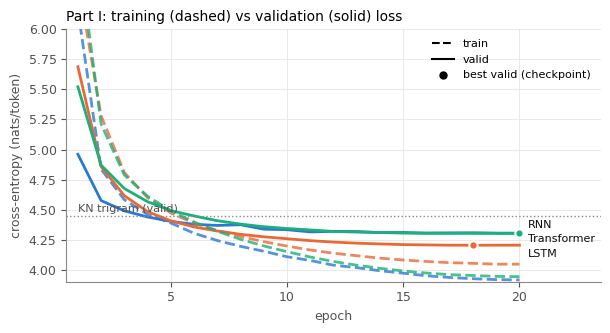

In [20]:
def curves(ax, names, title, labels=None, dy=None):
    """dy: vertical label offsets in points, to keep end-of-line labels from colliding."""
    labels, dy = labels or LABEL, dy or {}
    for n in names:
        ep = [e["epoch"] for e in train[n]["epochs"]]
        ax.plot(ep, [e["train_loss"] for e in train[n]["epochs"]], "--", color=C[n], alpha=0.8)
        v = [e["valid_loss"] for e in train[n]["epochs"]]
        ax.plot(ep, v, "-", color=C[n])
        b = int(np.argmin(v))
        ax.plot(ep[b], v[b], "o", color=C[n], ms=6, mec="white", mew=1.5)
        ax.annotate(labels[n], (ep[-1], v[-1]), xytext=(6, dy.get(n, 0)), textcoords="offset points",
                    color="#0b0b0b", va="center", fontsize=8)
    ax.set_xlabel("epoch"); ax.set_ylabel("cross-entropy (nats/token)")
    ax.set_title(title, loc="left", fontsize=10)
    ax.plot([], [], "k--", lw=1.5, label="train"); ax.plot([], [], "k-", lw=1.5, label="valid")
    ax.plot([], [], "ko", ms=5, label="best valid (checkpoint)")
    ax.legend(frameon=False, fontsize=8, loc="upper right")

fig, ax = plt.subplots(figsize=(6.2, 3.4))
curves(ax, ["rnn", "lstm", "transformer"], "Part I: training (dashed) vs validation (solid) loss",
       dy={"rnn": 6, "transformer": -4, "lstm": -6})
ax.axhline(ng["valid_ce"], color="#8a8984", lw=1, ls=":")
ax.annotate("KN trigram (valid)", (1, ng["valid_ce"]), xytext=(0, 3), textcoords="offset points",
            color="#52514e", fontsize=8)
ax.set_xlim(0.5, 23.5); ax.set_ylim(3.9, 6.0)
fig.tight_layout(); fig.savefig(FIG / "part1_curves.png", dpi=200); plt.show()

## Part I: generated text and repetition

In [21]:
gen = load("generations.json")
models = ["ngram", "rnn", "lstm", "transformer"]
print(pd.DataFrame({m: gen[m]["metrics"] | {"greedy_rep_trigram": gen[m]["greedy_metrics"]["repeated_trigram_rate"]}
                    for m in models + ["lstm_sgns", "lstm_glove"]}).T.to_markdown(floatfmt=".3f"))
for p in gen["ngram"]["samples"]:
    print(f"\n### {p}")
    for m in models:
        print(f"- {m:12s} | sample: {gen[m]['samples'][p]}")
        print(f"  {'':12s} | greedy: {gen[m]['greedy'][p]}")

|             |   distinct_1 |   distinct_2 |   repeated_trigram_rate |   greedy_rep_trigram |
|:------------|-------------:|-------------:|------------------------:|---------------------:|
| ngram       |        0.223 |        0.647 |                   0.004 |                0.364 |
| rnn         |        0.215 |        0.624 |                   0.000 |                0.450 |
| lstm        |        0.191 |        0.599 |                   0.001 |                0.543 |
| transformer |        0.207 |        0.624 |                   0.004 |                0.236 |
| lstm_sgns   |        0.187 |        0.602 |                   0.002 |                0.343 |
| lstm_glove  |        0.190 |        0.582 |                   0.008 |                0.493 |

### Emma could not
- ngram        | sample: do ; and , after harriet 's side , which they , if the loss of time to be very much . <eos> he is not fit on his side
               | greedy: be in town , and the two miss steeles , as she could

## Part II: embedding ablation (LSTM)

In [22]:
sg, gl = load("emb_sgns.json"), load("emb_glove.json")
rows = []
for n, emb in [("lstm", "random (trainable)"), ("lstm_sgns", "own SGNS (frozen)"), ("lstm_glove", "GloVe 6B (frozen)")]:
    t, e = train[n], ev[n]
    last = [x["valid_loss"] for x in t["epochs"]]
    rows.append({"embedding": emb, "trainable params": t["params_trainable"], "best epoch": t["best_epoch"],
                 "test PPL": e["test_ppl"], "best valid CE": t["best_valid_loss"],
                 "final valid CE": last[-1], "overfit gap (final-best)": last[-1] - min(last),
                 "train CE @best": t["epochs"][t["best_epoch"] - 1]["train_loss"],
                 "mean grad norm": np.mean([x["grad_norm_mean"] for x in t["epochs"]]),
                 "step-loss std (last epoch)": float(np.std(t["step_loss"][-len(t["step_loss"]) // t["hp"]["epochs"]:])),
                 "LM train time (s, median epoch x 20)": t["median_epoch_time_s"] * t["hp"]["epochs"],
                 "CPU tok/s": e["cpu_throughput"]["tokens_per_s"]})
part2 = pd.DataFrame(rows)
print(part2.to_markdown(index=False, floatfmt=".3f"))
print(f"\nSGNS training time: {sg['train_time_s']:.1f}s (separate from LM training)")
print(f"GloVe coverage: types {gl['type_coverage']:.2%}, tokens {gl['token_coverage']:.2%}, missing {gl['n_missing']}")
print("missing examples:", gl["missing"][:30])
print("SGNS neighbours:", sg["neighbours"]); print("GloVe neighbours:", gl["neighbours"])

| embedding          |   trainable params |   best epoch |   test PPL |   best valid CE |   final valid CE |   overfit gap (final-best) |   train CE @best |   mean grad norm |   step-loss std (last epoch) |   LM train time (s, median epoch x 20) |   CPU tok/s |
|:-------------------|-------------------:|-------------:|-----------:|----------------:|-----------------:|---------------------------:|-----------------:|-----------------:|-----------------------------:|---------------------------------------:|------------:|
| random (trainable) |            2559047 |           18 |     68.367 |           4.203 |            4.204 |                      0.001 |            4.053 |            0.226 |                        0.076 |                                136.450 |   12575.656 |
| own SGNS (frozen)  |            2092347 |           20 |     71.316 |           4.255 |            4.255 |                      0.000 |            4.174 |            0.221 |                        0.073 |        

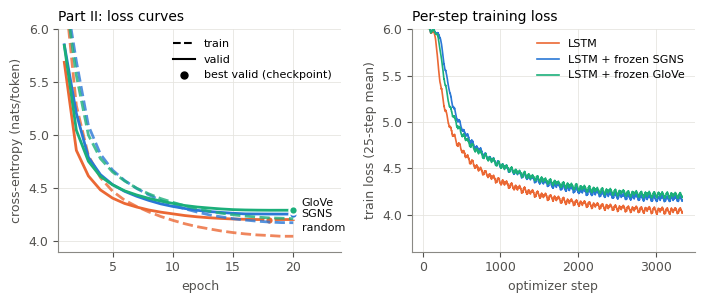

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.1))
curves(axes[0], ["lstm", "lstm_sgns", "lstm_glove"], "Part II: loss curves",
       labels={"lstm": "random", "lstm_sgns": "SGNS", "lstm_glove": "GloVe"},
       dy={"lstm_glove": 5, "lstm_sgns": 0, "lstm": -6})
axes[0].set_xlim(0.5, 24); axes[0].set_ylim(3.9, 6.0)
ax = axes[1]
k = 25
for n in ["lstm", "lstm_sgns", "lstm_glove"]:
    s = np.array(train[n]["step_loss"])
    sm = np.convolve(s, np.ones(k) / k, mode="valid")
    ax.plot(np.arange(len(sm)) + k, sm, color=C[n], lw=1.2, label=LABEL[n])
ax.set_xlabel("optimizer step"); ax.set_ylabel("train loss (25-step mean)")
ax.set_title("Per-step training loss", loc="left", fontsize=10)
ax.set_ylim(3.6, 6.0); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "part2_curves.png", dpi=200); plt.show()

In [24]:
for p in gen["ngram"]["samples"]:
    print(f"\n### {p}")
    for m in ["lstm", "lstm_sgns", "lstm_glove"]:
        print(f"- {m:12s} | {gen[m]['samples'][p]}")


### Emma could not
- lstm         | come . <eos> the child which had been all an attachment , with the whole , which he had been the little friend of it , nor having been more
- lstm_sgns    | know . <eos> the rest were so happy to get them , but the idea of their mind , her , and his spirits and her imagination from his having
- lstm_glove   | think the more , but if he will be satisfied for , which , there was an end of her , and as he could not fail herself in her

### It was a fine morning, and
- lstm         | be extremely much mistaken . <eos> they were so to make his own account . <eos> a man to be made in a hurry from mr. knightley , and though
- lstm_sgns    | that there was nothing to be done the pleasure , but she had never been very much a little of what it had already passed for her . <eos> elinor
- lstm_glove   | that one was better to be given . <eos> the child had been just to be the same of the subject . <eos> elinor found very well to her husband

### Mr. Knightley s

## 5. Part III: downstream sentiment classification (SST-2)

GLUE SST-2 has hidden test labels, so the official validation set (872 full sentences) is used as the held-out **test** set.
From training phrases with >= 5 words, 10,000 are sampled for training and 2,000 as a development set for choosing the
classifier's regularisation C (seed 42). Sentences are mapped to the Austen vocabulary.

Each sentence becomes a fixed-length vector from the **frozen** language model (eval mode):
* `last`: top-layer hidden state at the last real token (right padding is harmless because the models are causal);
* `mean`: average of top-layer hidden states over the real tokens, padding excluded.

The classifier is identical for every representation (StandardScaler + logistic regression, C in {0.001, 0.01, 0.1, 1}
chosen on dev). Reference points: majority class, and the average of the frozen GloVe vectors with no LM involved.
Bootstrap (2000 resamples) gives 95% intervals and paired differences.

In [25]:
import json
import re
from pathlib import Path

import numpy as np
import torch
from datasets import load_dataset
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


SEED = 42
N_TRAIN, N_DEV, MIN_WORDS = 10_000, 2_000, 5
REPS = [("lstm", "last"), ("lstm", "mean"), ("transformer", "last"), ("transformer", "mean"),
        ("rnn", "last"), ("rnn", "mean"), ("lstm_sgns", "mean"), ("lstm_glove", "mean")]
NEGATION = re.compile(r"\b(not|no|never|n't|nothing|neither|nor|without|hardly)\b")


def load_sst2(vocab):
    ds = load_dataset("nyu-mll/glue", "sst2")
    tr = [(s, l) for s, l in zip(ds["train"]["sentence"], ds["train"]["label"])
          if len(s.split()) >= MIN_WORDS]
    rng = np.random.default_rng(SEED)
    idx = rng.permutation(len(tr))
    train = [tr[i] for i in idx[:N_TRAIN]]
    dev = [tr[i] for i in idx[N_TRAIN:N_TRAIN + N_DEV]]
    test = list(zip(ds["validation"]["sentence"], ds["validation"]["label"]))

    def enc(rows):
        # SST-2 is already lower-cased and tokenised (e.g. "it 's", "does n't") -> split on spaces
        toks = [s.split() for s, _ in rows]
        ids = [vocab.encode(t) for t in toks]
        return {"text": [s.strip() for s, _ in rows], "tokens": toks, "ids": ids,
                "y": np.array([l for _, l in rows])}
    return enc(train), enc(dev), enc(test)


@torch.no_grad()
def features(model, ids_list, pooling, device, batch_size=256):
    out = []
    max_len = getattr(model, "context", 10_000)
    for i in range(0, len(ids_list), batch_size):
        batch = [ids[:max_len] for ids in ids_list[i:i + batch_size]]
        lens = torch.tensor([len(b) for b in batch], device=device)
        x = torch.full((len(batch), int(lens.max())), PAD, dtype=torch.long, device=device)
        for j, b in enumerate(batch):
            x[j, :len(b)] = torch.tensor(b)
        h, _ = model.encode(x)                                 # (B, T, H); causal => right padding is harmless
        if pooling == "last":
            v = h[torch.arange(len(batch), device=device), lens - 1]
        else:
            mask = (x != PAD).unsqueeze(-1).float()
            v = (h * mask).sum(1) / mask.sum(1)
        out.append(v.cpu().numpy())
    return np.concatenate(out)


def glove_avg(ids_list, E):
    return np.stack([E[ids].mean(0) for ids in ids_list])


def fit_eval(Xtr, ytr, Xdev, ydev, Xte, yte):
    best = None
    for C in [0.001, 0.01, 0.1, 1.0]:
        clf = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000))
        clf.fit(Xtr, ytr)
        acc = accuracy_score(ydev, clf.predict(Xdev))
        if best is None or acc > best[0]:
            best = (acc, C, clf)
    dev_acc, C, clf = best
    pred = clf.predict(Xte)
    return {"C": C, "dev_acc": dev_acc, "test_acc": accuracy_score(yte, pred),
            "test_macro_f1": f1_score(yte, pred, average="macro"),
            "train_acc": accuracy_score(ytr, clf.predict(Xtr))}, pred


def run_downstream():
    torch.manual_seed(SEED)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    _, vocab, _ = build_corpus()
    train, dev, test = load_sst2(vocab)
    unk = {k: float(np.mean([i == UNK for ids in d["ids"] for i in ids]))
           for k, d in [("train", train), ("dev", dev), ("test", test)]}
    print(f"SST-2 sizes: {len(train['y'])}/{len(dev['y'])}/{len(test['y'])}, "
          f"<unk> rate under the Austen vocab: {unk}")

    results = {"setup": {"n_train": len(train["y"]), "n_dev": len(dev["y"]), "n_test": len(test["y"]),
                         "min_words": MIN_WORDS, "unk_rate": unk, "seed": SEED}, "reps": {}}
    preds = {}
    maj = int(np.bincount(train["y"]).argmax())
    results["reps"]["majority"] = {"test_acc": float(np.mean(test["y"] == maj)),
                                   "test_macro_f1": f1_score(test["y"], np.full(len(test["y"]), maj),
                                                             average="macro")}
    E = np.load(ROOT / "data" / "glove_100.npy")
    r, preds["glove_avg"] = fit_eval(glove_avg(train["ids"], E), train["y"], glove_avg(dev["ids"], E),
                                     dev["y"], glove_avg(test["ids"], E), test["y"])
    results["reps"]["glove_avg"] = r

    cache = {}
    for name, pooling in REPS:
        if name not in cache:
            cache[name] = load_model(name, len(vocab), device)[0]
        m = cache[name]
        X = [features(m, d["ids"], pooling, device) for d in (train, dev, test)]
        key = f"{name}/{pooling}"
        r, preds[key] = fit_eval(X[0], train["y"], X[1], dev["y"], X[2], test["y"])
        r["dim"] = X[0].shape[1]
        results["reps"][key] = r
        print(f"{key:20s} test acc {r['test_acc']:.3f}  macro-F1 {r['test_macro_f1']:.3f} "
              f"(dev {r['dev_acc']:.3f}, train {r['train_acc']:.3f}, C={r['C']})")
    print(f"{'glove_avg':20s} test acc {results['reps']['glove_avg']['test_acc']:.3f}; "
          f"majority {results['reps']['majority']['test_acc']:.3f}")

    # uncertainty: bootstrap 95% CI of test accuracy (n=872) and paired bootstrap for key pairs
    y = test["y"]
    rng = np.random.default_rng(SEED)
    boot = rng.integers(0, len(y), (2000, len(y)))
    for key, p in preds.items():
        accs = (p[boot] == y[boot]).mean(1)
        results["reps"][key]["test_acc_ci95"] = [float(np.percentile(accs, 2.5)),
                                                 float(np.percentile(accs, 97.5))]
    pairs = [("lstm/mean", "lstm/last"), ("transformer/mean", "lstm/mean"),
             ("lstm_glove/mean", "lstm/mean"), ("lstm_sgns/mean", "lstm/mean"),
             ("glove_avg", "lstm_glove/mean")]
    results["paired_bootstrap"] = {}
    for a, b in pairs:
        diff = ((preds[a][boot] == y[boot]).mean(1) - (preds[b][boot] == y[boot]).mean(1))
        results["paired_bootstrap"][f"{a} - {b}"] = {
            "diff": float(np.mean(preds[a] == y) - np.mean(preds[b] == y)),
            "ci95": [float(np.percentile(diff, 2.5)), float(np.percentile(diff, 97.5))],
            "p_le_0": float(np.mean(diff <= 0))}
    np.savez(ROOT / "results" / "downstream_preds.npz", y=y, **{k.replace("/", "__"): v for k, v in preds.items()})

    # error analysis on the test set
    neg = np.array([bool(NEGATION.search(t)) for t in test["text"]])
    oov = np.array([np.mean([i == UNK for i in ids]) for ids in test["ids"]])
    analysis = {"negation_share": float(neg.mean())}
    for key, p in preds.items():
        correct = p == y
        analysis[key] = {"acc_with_negation": float(correct[neg].mean()),
                         "acc_without_negation": float(correct[~neg].mean()),
                         "oov_rate_correct": float(oov[correct].mean()),
                         "oov_rate_wrong": float(oov[~correct].mean())}
    a, b = "lstm/mean", "transformer/mean"
    examples = {"both_wrong": [], f"only_{a}_right": [], f"only_{b}_right": []}
    for i in range(len(y)):
        ca, cb = preds[a][i] == y[i], preds[b][i] == y[i]
        tag = None if ca and cb else "both_wrong" if not (ca or cb) else \
            f"only_{a}_right" if ca else f"only_{b}_right"
        if tag:
            examples[tag].append({"text": test["text"][i], "label": int(y[i]),
                                  "oov_rate": float(oov[i]), "negation": bool(neg[i]),
                                  "visible": " ".join(vocab.decode(test["ids"][i]))})
    analysis["counts"] = {k: len(v) for k, v in examples.items()}
    rng = np.random.default_rng(SEED)
    analysis["examples"] = {k: [v[j] for j in rng.permutation(len(v))[:8]] for k, v in examples.items()}
    results["error_analysis"] = analysis
    with open(ROOT / "results" / "downstream.json", "w") as f:
        json.dump(results, f, indent=2)
    print(json.dumps({k: v for k, v in analysis.items() if k != "examples"}, indent=1))

In [26]:
run_downstream()

SST-2 sizes: 10000/2000/872, <unk> rate under the Austen vocab: {'train': 0.26041467791820994, 'dev': 0.2604977566437857, 'test': 0.2574210958582659}


lstm/last            test acc 0.556  macro-F1 0.512 (dev 0.584, train 0.591, C=0.01)


lstm/mean            test acc 0.602  macro-F1 0.598 (dev 0.632, train 0.635, C=0.01)


transformer/last     test acc 0.537  macro-F1 0.472 (dev 0.596, train 0.591, C=0.01)


transformer/mean     test acc 0.632  macro-F1 0.625 (dev 0.613, train 0.629, C=0.1)


rnn/last             test acc 0.534  macro-F1 0.467 (dev 0.569, train 0.596, C=0.001)


rnn/mean             test acc 0.622  macro-F1 0.611 (dev 0.622, train 0.622, C=0.001)


lstm_sgns/mean       test acc 0.630  macro-F1 0.626 (dev 0.650, train 0.643, C=0.01)


lstm_glove/mean      test acc 0.655  macro-F1 0.651 (dev 0.655, train 0.656, C=0.01)
glove_avg            test acc 0.731; majority 0.509


{
 "negation_share": 0.22477064220183487,
 "glove_avg": {
  "acc_with_negation": 0.6836734693877551,
  "acc_without_negation": 0.7440828402366864,
  "oov_rate_correct": 0.25917544496243783,
  "oov_rate_wrong": 0.2638446870487452
 },
 "lstm/last": {
  "acc_with_negation": 0.4744897959183674,
  "acc_without_negation": 0.5798816568047337,
  "oov_rate_correct": 0.25978614511084414,
  "oov_rate_wrong": 0.26124542511309723
 },
 "lstm/mean": {
  "acc_with_negation": 0.5969387755102041,
  "acc_without_negation": 0.6035502958579881,
  "oov_rate_correct": 0.25494670136287784,
  "oov_rate_wrong": 0.2687355668069659
 },
 "transformer/last": {
  "acc_with_negation": 0.41836734693877553,
  "acc_without_negation": 0.5710059171597633,
  "oov_rate_correct": 0.26469644256157926,
  "oov_rate_wrong": 0.2554958534126458
 },
 "transformer/mean": {
  "acc_with_negation": 0.6479591836734694,
  "acc_without_negation": 0.6272189349112426,
  "oov_rate_correct": 0.259217172570024,
  "oov_rate_wrong": 0.2625221115

## Part III: SST-2 from frozen LM representations

In [27]:
ds = load("downstream.json")
print(ds["setup"])
rows = []
for k, r in ds["reps"].items():
    lm = k.split("/")[0]
    rows.append({"representation": k, "dim": r.get("dim", ""), "C": r.get("C", ""),
                 "test acc": r["test_acc"],
                 "95% CI": "-" if "test_acc_ci95" not in r else f"[{r['test_acc_ci95'][0]:.3f}, {r['test_acc_ci95'][1]:.3f}]",
                 "test macro-F1": r["test_macro_f1"],
                 "train acc": r.get("train_acc", np.nan),
                 "LM test PPL (Austen)": ev[lm]["test_ppl"] if lm in ev else np.nan})
part3 = pd.DataFrame(rows)
print(part3.to_markdown(index=False, floatfmt=".3f"))
print("paired bootstrap (2000 resamples) of accuracy differences:")
for k, v in ds["paired_bootstrap"].items():
    print(f"  {k:35s} diff {v['diff']:+.3f}  CI95 [{v['ci95'][0]:+.3f}, {v['ci95'][1]:+.3f}]  P(diff<=0)={v['p_le_0']:.3f}")

{'n_train': 10000, 'n_dev': 2000, 'n_test': 872, 'min_words': 5, 'unk_rate': {'train': 0.26041467791820994, 'dev': 0.2604977566437857, 'test': 0.2574210958582659}, 'seed': 42}
| representation   |   dim |     C |   test acc | 95% CI         |   test macro-F1 |   train acc |   LM test PPL (Austen) |
|:-----------------|------:|------:|-----------:|:---------------|----------------:|------------:|-----------------------:|
| majority         |       |       |      0.509 | -              |           0.337 |     nan     |                nan     |
| glove_avg        |       | 1.000 |      0.731 | [0.697, 0.758] |           0.730 |       0.713 |                nan     |
| lstm/last        |   256 | 0.010 |      0.556 | [0.522, 0.587] |           0.512 |       0.591 |                 68.367 |
| lstm/mean        |   256 | 0.010 |      0.602 | [0.569, 0.633] |           0.598 |       0.635 |                 68.367 |
| transformer/last |   128 | 0.010 |      0.537 | [0.503, 0.570] |           0.4

In [28]:
ea = ds["error_analysis"]
print("share of test sentences with negation:", round(ea["negation_share"], 3))
print(pd.DataFrame({k: v for k, v in ea.items() if isinstance(v, dict) and "acc_with_negation" in v}).T.to_markdown(floatfmt=".3f"))
print(ea["counts"])
for tag, exs in ea["examples"].items():
    print(f"\n## {tag}")
    for e in exs[:6]:
        print(f"- [{'pos' if e['label'] else 'neg'}] oov={e['oov_rate']:.2f} | {e['text']}\n    seen as: {e['visible']}")

share of test sentences with negation: 0.225
|                  |   acc_with_negation |   acc_without_negation |   oov_rate_correct |   oov_rate_wrong |
|:-----------------|--------------------:|-----------------------:|-------------------:|-----------------:|
| glove_avg        |               0.684 |                  0.744 |              0.259 |            0.264 |
| lstm/last        |               0.474 |                  0.580 |              0.260 |            0.261 |
| lstm/mean        |               0.597 |                  0.604 |              0.255 |            0.269 |
| transformer/last |               0.418 |                  0.571 |              0.265 |            0.255 |
| transformer/mean |               0.648 |                  0.627 |              0.259 |            0.263 |
| rnn/last         |               0.464 |                  0.555 |              0.264 |            0.256 |
| rnn/mean         |               0.643 |                  0.615 |              0.257 |   

## Cross-part: LM perplexity vs downstream accuracy

|             |   LM test PPL |   SST-2 acc (mean-pool) |
|:------------|--------------:|------------------------:|
| lstm        |        68.367 |                   0.602 |
| lstm_sgns   |        71.316 |                   0.630 |
| lstm_glove  |        73.730 |                   0.655 |
| transformer |        73.861 |                   0.632 |
| rnn         |        74.554 |                   0.622 |
Spearman (PPL vs acc): SignificanceResult(statistic=np.float64(0.3), pvalue=np.float64(0.6238376647810728))


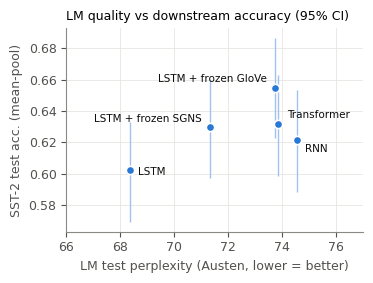

In [29]:
names = ["rnn", "lstm", "transformer", "lstm_sgns", "lstm_glove"]
xs = [ev[n]["test_ppl"] for n in names]
ys = [ds["reps"][f"{n}/mean"]["test_acc"] for n in names]
print(pd.DataFrame({"LM test PPL": xs, "SST-2 acc (mean-pool)": ys}, index=names)
      .sort_values("LM test PPL").to_markdown(floatfmt=".3f"))
from scipy.stats import spearmanr
print("Spearman (PPL vs acc):", spearmanr(xs, ys))
fig, ax = plt.subplots(figsize=(3.8, 2.9))
pos = {"lstm": ((6, -3), "left"), "lstm_sgns": ((-6, 4), "right"), "lstm_glove": ((-6, 4), "right"),
       "transformer": ((6, 4), "left"), "rnn": ((6, -9), "left")}
for n, x, y in zip(names, xs, ys):
    lo, hi = ds["reps"][f"{n}/mean"]["test_acc_ci95"]
    ax.errorbar(x, y, yerr=[[y - lo], [hi - y]], fmt="o", color="#2a78d6", ms=6, mec="white", mew=1.2,
                elinewidth=1, capsize=0, ecolor="#9fc3ee")
    ax.annotate(LABEL[n], (x, y), xytext=pos[n][0], textcoords="offset points", ha=pos[n][1],
                fontsize=7.5, color="#0b0b0b")
ax.set_xlabel("LM test perplexity (Austen, lower = better)"); ax.set_ylabel("SST-2 test acc. (mean-pool)")
ax.set_title("LM quality vs downstream accuracy (95% CI)", loc="left", fontsize=9)
ax.set_xlim(66, 77)
fig.tight_layout(); fig.savefig(FIG / "ppl_vs_acc.png", dpi=200); plt.show()

## 7. Where to find the discussion

The interpretation of these results (observations vs hypotheses, trade-offs, limitations and lessons) is in
`report/report.pdf`.

**Headline findings (test perplexity, single seed):** LSTM 68.4 < SGNS-LSTM 71.3 < GloVe-LSTM 73.7 ~ Transformer 73.9 ~ RNN 74.6 < Kneser-Ney trigram 87.6.
Frozen pretrained embeddings did not improve LM perplexity, but frozen GloVe gave the best mean-pooled SST-2 features (0.655 acc), while the best LM (LSTM) gave the worst-ranked mean-pooled features among the LSTMs, so LM perplexity is a poor proxy for downstream transfer here.